<a href="https://colab.research.google.com/github/sylle321/Hotel_booking/blob/main/BA305_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px                          # interactive plots (pre-installed on Colab)
from sklearn.preprocessing import StandardScaler     # does the scaling for us
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from tqdm import tqdm
from sklearn.pipeline import Pipeline
# Libraries used in the Session 13 decision tree lab
from sklearn import tree
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score, GridSearchCV
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)
path = "hotels.csv"
df = pd.read_csv(path)
#Shows each columns data type and number of non-null values.
df.info()
     

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal            

In [2]:
#Counts distinct values in each column of the dataframe.
df.nunique()

hotel                                2
is_canceled                          2
lead_time                          479
arrival_date_year                    3
arrival_date_month                  12
arrival_date_week_number            53
arrival_date_day_of_month           31
stays_in_weekend_nights             17
stays_in_week_nights                35
adults                              14
children                             5
babies                               5
meal                                 5
country                            177
market_segment                       8
distribution_channel                 5
is_repeated_guest                    2
previous_cancellations              15
previous_bookings_not_canceled      73
reserved_room_type                  10
assigned_room_type                  12
booking_changes                     21
deposit_type                         3
agent                              333
company                            352
days_in_waiting_list     

In [3]:
# Convert hotel to a dummy variable:
# Resort Hotel = 0, City Hotel = 1
df['hotel'] = df['hotel'].map({
    'Resort Hotel': 0,
    'City Hotel': 1
})

df.head()

# Create dummy variables for the other categorical variables
categorical_cols = [
    'deposit_type',
    'market_segment',
    'customer_type',
    'reserved_room_type'
]

df_encoded = pd.get_dummies(
    df,
    columns=categorical_cols,
    drop_first=True,
    dtype=int
)

df_encoded.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 49 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  int64  
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal            

In [4]:
# Selecting the columns of interest for analysis
# Making sure unrelated columns are not included in the analysis.
cols = [
    "hotel",
    "is_canceled",
    "lead_time",
    "deposit_type",
    "previous_cancellations",
    "previous_bookings_not_canceled",
    "customer_type",
    "booking_changes",
    "is_repeated_guest",
    "market_segment",
    "total_of_special_requests",
    "stays_in_weekend_nights",
    "stays_in_week_nights",
    "reserved_room_type",
    "adr",
    "distribution_channel",
    "arrival_date_month"
]

hotel_selected = df[cols]

hotel_selected.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 17 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  int64  
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   deposit_type                    119390 non-null  object 
 4   previous_cancellations          119390 non-null  int64  
 5   previous_bookings_not_canceled  119390 non-null  int64  
 6   customer_type                   119390 non-null  object 
 7   booking_changes                 119390 non-null  int64  
 8   is_repeated_guest               119390 non-null  int64  
 9   market_segment                  119390 non-null  object 
 10  total_of_special_requests       119390 non-null  int64  
 11  stays_in_weekend_nights         119390 non-null  int64  
 12  stays_in_week_ni

In [5]:
#Cleaning the data by removing rows with any missing values and resetting the index.
hotel_clean = hotel_selected.dropna(how="any") #Removes rows with any missing values.
hotel_clean = hotel_clean.reset_index(drop=True) #resets the index

print(hotel_selected.shape)
print(hotel_clean.shape)

(119390, 17)
(119390, 17)


In [6]:
#Checking cancelation counts and proportions in the cleaned dataset.
print(hotel_clean["is_canceled"].value_counts()) #Gives the count of each unique value in the "is_canceled" column.

print(
    hotel_clean["is_canceled"].value_counts(normalize=True) # Gives the proportion of each unique value in the "is_canceled" column.
)


is_canceled
0    75166
1    44224
Name: count, dtype: int64
is_canceled
0    0.629584
1    0.370416
Name: proportion, dtype: float64


In [7]:
# Calculate the correlation using PCA lab's code as reference.
# We exclude categorical string columns and only keep truly numeric columns
numeric_cols = [
    "is_canceled",
    "lead_time",
    "previous_cancellations",
    "previous_bookings_not_canceled",
    "booking_changes",
    "is_repeated_guest",
    "total_of_special_requests",
    "stays_in_weekend_nights",
    "stays_in_week_nights",
    "adr"
]

hotel_numeric = hotel_clean[numeric_cols]

corr_mat = hotel_numeric.corr()

corr_mat.round(4)

,is_canceled,lead_time,previous_cancellations,previous_bookings_not_canceled,booking_changes,is_repeated_guest,total_of_special_requests,stays_in_weekend_nights,stays_in_week_nights,adr
is_canceled,1.0000,0.2931,0.1101,-0.0574,-0.1444,-0.0848,-0.2347,-0.0018,0.0248,0.0476
lead_time,0.2931,1.0000,0.0860,-0.0735,0.0001,-0.1244,-0.0957,0.0857,0.1658,-0.0631
previous_cancellations,0.1101,0.0860,1.0000,0.1527,-0.0270,0.0823,-0.0484,-0.0128,-0.0140,-0.0656
previous_bookings_not_canceled,-0.0574,-0.0735,0.1527,1.0000,0.0116,0.4181,0.0378,-0.0427,-0.0487,-0.0721
booking_changes,-0.1444,0.0001,-0.0270,0.0116,1.0000,0.0121,0.0528,0.0633,0.0962,0.0196
is_repeated_guest,-0.0848,-0.1244,0.0823,0.4181,0.0121,1.0000,0.0131,-0.0872,-0.0972,-0.1343
total_of_special_requests,-0.2347,-0.0957,-0.0484,0.0378,0.0528,0.0131,1.0000,0.0727,0.0682,0.1722
stays_in_weekend_nights,-0.0018,0.0857,-0.0128,-0.0427,0.0633,-0.0872,0.0727,1.0000,0.4990,0.0493
stays_in_week_nights,0.0248,0.1658,-0.0140,-0.0487,0.0962,-0.0972,0.0682,0.4990,1.0000,0.0652
adr,0.0476,-0.0631,-0.0656,-0.0721,0.0196,-0.1343,0.1722,0.0493,0.0652,1.0000


In [8]:
# Correlation with is_canceled only
corr_mat[["is_canceled"]].round(3)

,is_canceled
is_canceled,1.000
lead_time,0.293
previous_cancellations,0.110
previous_bookings_not_canceled,-0.057
booking_changes,-0.144
is_repeated_guest,-0.085
total_of_special_requests,-0.235
stays_in_weekend_nights,-0.002
stays_in_week_nights,0.025
adr,0.048


In [9]:
# Keep the existing nine numeric predictors
X = hotel_numeric.drop(columns=["is_canceled"]).copy()

# Create deposit-type dummies; No Deposit is the reference category
deposit_dummies = pd.DataFrame({
    "deposit_type_Non Refund": (
        hotel_clean["deposit_type"] == "Non Refund"
    ).astype(int),

    "deposit_type_Refundable": (
        hotel_clean["deposit_type"] == "Refundable"
    ).astype(int)
})

# Add the two dummy variables to the model inputs
X = X.join(deposit_dummies)

# Define the target variable
y = hotel_clean["is_canceled"]

# Keep the same train/test split settings
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=0,
    stratify=y
)

# Check that there are now 11 predictors
print("Predictors:", X.columns.tolist())
print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

Predictors: ['lead_time', 'previous_cancellations', 'previous_bookings_not_canceled', 'booking_changes', 'is_repeated_guest', 'total_of_special_requests', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adr', 'deposit_type_Non Refund', 'deposit_type_Refundable']
Training set: (95512, 11)
Testing set: (23878, 11)


Best k: 2
Best cross-validation accuracy: 0.8


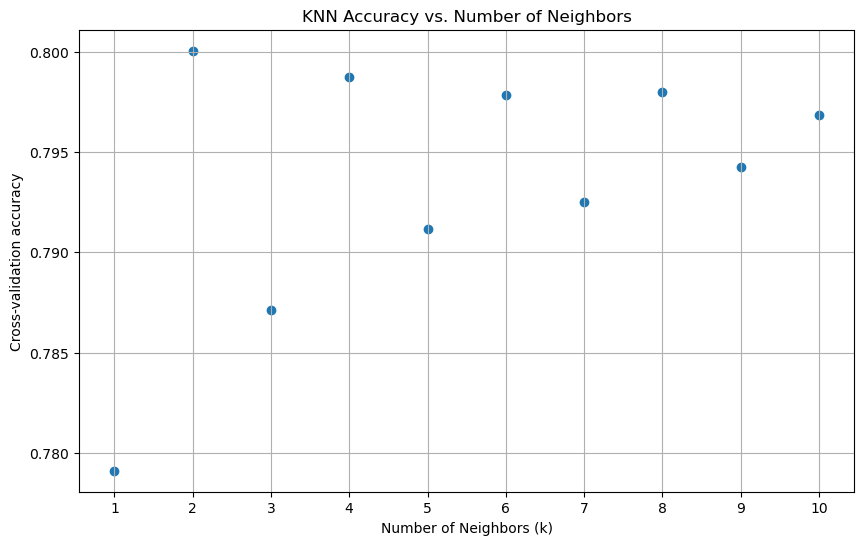

Test accuracy: 0.8008627188206717
Confusion Matrix:
[[14018  1015]
 [ 3740  5105]]


In [10]:
# Combine scaling and KNN in one pipeline
knn_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier())
])

# Compare different numbers of neighbors
k_values = list(range(1, 11))

# Choose k using cross-validation on training data
knn_search = GridSearchCV(
    knn_pipeline,
    {"knn__n_neighbors": k_values},
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

# Learn scaling separately within each training fold
knn_search.fit(X_train, y_train)

# Retrieve the best model, refitted on all training data
knn = knn_search.best_estimator_

print("Best k:", knn_search.best_params_["knn__n_neighbors"])
print(
    "Best cross-validation accuracy:",
    round(knn_search.best_score_, 3)
)

# Extract average validation accuracy for each k
accuracies = knn_search.cv_results_["mean_test_score"]

# Plot cross-validation accuracy
plt.figure(figsize=(10, 6))
plt.scatter(k_values, accuracies)
plt.xlabel("Number of Neighbors (k)")
plt.ylabel("Cross-validation accuracy")
plt.title("KNN Accuracy vs. Number of Neighbors")
plt.xticks(k_values)
plt.grid(True)
plt.show()

# Predict test bookings; the pipeline handles scaling
y_pred = knn.predict(X_test)

print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred, labels=[0, 1]))

In [11]:
baseline_accuracy = y_test.value_counts(normalize=True).max()
print("Baseline Accuracy:", baseline_accuracy)
# calculate the baseline accuracy
# compare with the knn-model accuracy
# knn-model's accuracy greater than the baseline

Baseline Accuracy: 0.6295753413183683


In [12]:
from sklearn.metrics import precision_score, recall_score, f1_score

precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)

Precision: 0.8341503267973857
Recall: 0.5771622385528548
F1 Score: 0.6822586034079519


In [13]:
# Create a full tree without limits on depth or leaf size
full_clf = DecisionTreeClassifier(random_state=0)

# Learn cancellation patterns from the training data
full_clf.fit(X_train, y_train)

# Count all decision nodes and leaves
print("Number of nodes:", full_clf.tree_.node_count)

# Predict outcomes for training and test bookings
y_pred_train = full_clf.predict(X_train)
y_pred_full = full_clf.predict(X_test)

# Measure how closely the tree fits the training data
print(
    "Training accuracy:",
    round(accuracy_score(y_train, y_pred_train), 3)
)

# Measure performance on bookings not used for training
print(
    "Testing accuracy:",
    round(accuracy_score(y_test, y_pred_full), 3)
)

# Rows = actual classes; columns = predicted classes
# Class order: 0 = not canceled, 1 = canceled
print("Confusion matrix on test data:")
print(confusion_matrix(y_test, y_pred_full, labels=[0, 1]))

Number of nodes: 38727
Training accuracy: 0.984
Testing accuracy: 0.79
Confusion matrix on test data:
[[12512  2521]
 [ 2497  6348]]


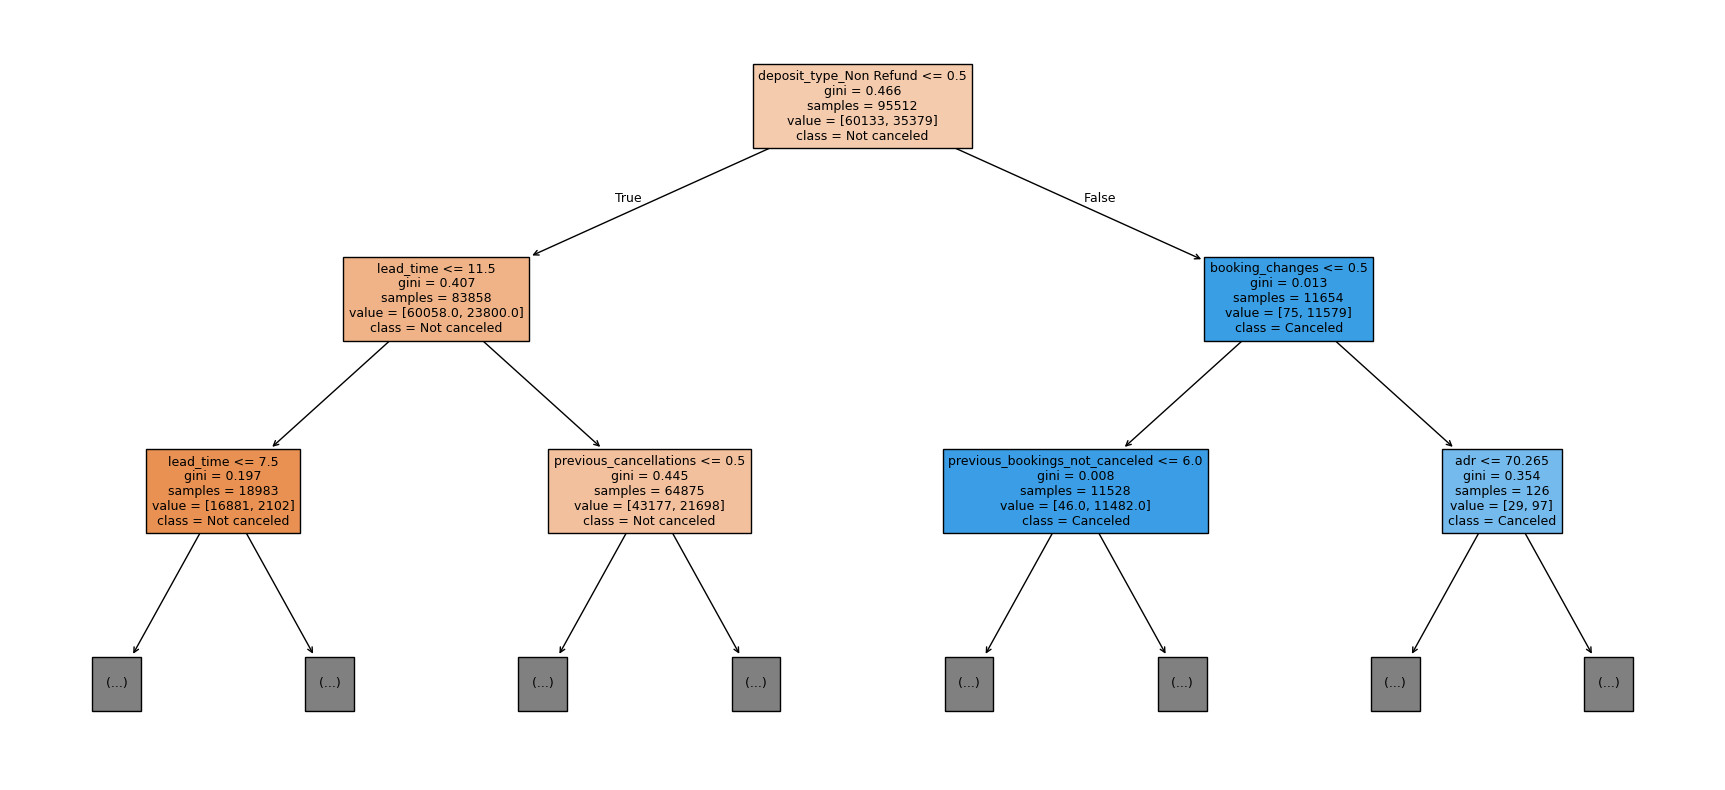

In [14]:
# Set the size of the tree diagram
plt.figure(figsize=(22, 10))

tree.plot_tree(
    full_clf,
    max_depth=2,  # Display the top three levels; the model stays unchanged
    feature_names=list(X_train.columns),  # Label splits with predictor names
    class_names=["Not canceled", "Canceled"],  # Label the two outcomes
    filled=True,  # Color nodes by their class composition
    fontsize=9
)

# Display the diagram
plt.show()

In [15]:
# Create a tree using the settings selected by cross-validation
clf = DecisionTreeClassifier(
    max_depth=20,              # Allow deeper patterns than the previous depth of 10
    min_samples_split=40,      # A node needs at least 40 bookings before splitting
    min_samples_leaf=20,       # Each leaf must contain at least 20 bookings
    min_impurity_decrease=0.01,   # Allow small improvements to justify a split
    criterion="gini",          # Prefer splits that separate the two classes
    random_state=0             # Make the results reproducible
)

# Learn cancellation patterns from the training data
clf.fit(X_train, y_train)

# Predict outcomes for training and test bookings
y_pred_train_tree = clf.predict(X_train)
y_pred_tree = clf.predict(X_test)

# Compare training and test accuracy to assess generalization
print(
    "Training accuracy:",
    round(accuracy_score(y_train, y_pred_train_tree), 3)
)

print(
    "Testing accuracy:",
    round(accuracy_score(y_test, y_pred_tree), 3)
)

# Rows = actual outcomes; columns = predicted outcomes
# Class order: 0 = not canceled, 1 = canceled
print("Confusion matrix on test data:")
print(confusion_matrix(y_test, y_pred_tree, labels=[0, 1]))

Training accuracy: 0.767
Testing accuracy: 0.768
Confusion matrix on test data:
[[14993    40]
 [ 5509  3336]]


In [16]:
# Create a tree using the settings selected by cross-validation
clf = DecisionTreeClassifier(
    max_depth=20,              # Allow deeper patterns than the previous depth of 10
    min_samples_split=40,      # A node needs at least 40 bookings before splitting
    min_samples_leaf=20,       # Each leaf must contain at least 20 bookings
    min_impurity_decrease=0,   # Allow smaller improvements to justify a split
    criterion="gini",          # Prefer splits that separate the two classes
    random_state=0             # Make the results reproducible
)

# Learn cancellation patterns from the training data
clf.fit(X_train, y_train)

# Predict outcomes for training and test bookings
y_pred_train_tree = clf.predict(X_train)
y_pred_tree = clf.predict(X_test)

# Compare training and test accuracy to assess generalization
print(
    "Training accuracy:",
    round(accuracy_score(y_train, y_pred_train_tree), 3)
)

print(
    "Testing accuracy:",
    round(accuracy_score(y_test, y_pred_tree), 3)
)

# Rows = actual outcomes; columns = predicted outcomes
# Class order: 0 = not canceled, 1 = canceled
print("Confusion matrix on test data:")
print(confusion_matrix(y_test, y_pred_tree, labels=[0, 1]))

Training accuracy: 0.824
Testing accuracy: 0.799
Confusion matrix on test data:
[[13615  1418]
 [ 3387  5458]]


In [17]:
# Train and validate the tree across five folds of the training data
accuracy_scores = cross_val_score(
    clf,
    X_train,
    y_train,
    cv=5,                # Use five validation rounds
    scoring="accuracy"   # Evaluate the proportion of correct predictions
)

# Display accuracy for each validation fold
print(
    "Accuracy scores of each fold:",
    [round(acc, 3) for acc in accuracy_scores]
)

# Calculate average accuracy across the five folds
print(
    "5-fold cross-validation mean accuracy:",
    round(accuracy_scores.mean(), 3)
)

Accuracy scores of each fold: [0.794, 0.795, 0.795, 0.794, 0.787]
5-fold cross-validation mean accuracy: 0.793


In [18]:
# Define the parameter values to compare
param_grid = {
    "max_depth": [5, 10, 20],               # Compare different depth limits
    "min_samples_leaf": [20, 50, 100],      # Compare minimum leaf sizes
    "min_impurity_decrease": [0, 0.001, 0.01]  # Compare split restrictions
}

# Compare all 27 combinations using five-fold cross-validation
gridSearch = GridSearchCV(
    DecisionTreeClassifier(random_state=0),
    param_grid,
    cv=5,                # Validate each combination across five folds
    scoring="accuracy",  # Select settings with the highest mean accuracy
    n_jobs=-1            # Use all available CPU cores
)

# Search using only the training data
gridSearch.fit(X_train, y_train)

# Display the best validation score and parameter combination
print("Best cross-validation accuracy:", gridSearch.best_score_)
print("Best parameters:", gridSearch.best_params_)

# Retrieve the best model, automatically refitted on all training data
best_clf = gridSearch.best_estimator_

# Predict outcomes for the held-out test bookings
y_pred_best_tree = best_clf.predict(X_test)

Best cross-validation accuracy: 0.7929997992411767
Best parameters: {'max_depth': 20, 'min_impurity_decrease': 0, 'min_samples_leaf': 20}


In [19]:
# Create a forest that combines predictions from 500 trees
rf = RandomForestClassifier(
    n_estimators=500,  # Number of trees in the forest
    random_state=0,   # Make the results reproducible
    criterion="gini", # Evaluate splits using Gini impurity
    n_jobs=-1         # Train trees using all available CPU cores
)

# Train the forest using the training bookings
rf.fit(X_train, y_train)

# Predict cancellation outcomes for the test bookings
y_pred_rf = rf.predict(X_test)

# Measure how closely the forest fits the training data
print(
    "Training accuracy:",
    round(accuracy_score(y_train, rf.predict(X_train)), 3)
)

# Measure performance on unseen test bookings
print(
    "Testing accuracy:",
    round(accuracy_score(y_test, y_pred_rf), 3)
)

# Show correct predictions, false alarms, and missed cancellations
print("Confusion matrix on test data:")
print(confusion_matrix(y_test, y_pred_rf, labels=[0, 1]))

Training accuracy: 0.984
Testing accuracy: 0.823
Confusion matrix on test data:
[[13508  1525]
 [ 2699  6146]]


In [20]:
# Find the most common outcome in the training data
majority_class = y_train.mode().iloc[0]

# Baseline: predict this outcome for every test booking
y_pred_baseline = np.full(len(y_test), majority_class)

# Collect each model's predictions for the same test bookings
predictions = {
    "Baseline": y_pred_baseline,
    "Full decision tree": y_pred_full,
    "Reduced decision tree": y_pred_tree,
    "Tuned decision tree": y_pred_best_tree,
    "Random forest": y_pred_rf
}

# Create an empty list to store evaluation results
results = []

# Calculate the same metrics for each model
for model_name, prediction in predictions.items():
    results.append({
        "Model": model_name,

        # Proportion of all bookings classified correctly
        "Accuracy": accuracy_score(y_test, prediction),

        # Proportion of flagged cancellations that actually canceled
        "Precision": precision_score(
            y_test, prediction, zero_division=0
        ),

        # Proportion of actual cancellations identified by the model
        "Recall": recall_score(
            y_test, prediction, zero_division=0
        ),

        # Harmonic mean of cancellation precision and recall
        "F1": f1_score(
            y_test, prediction, zero_division=0
        )
    })

# Convert the results into a table with model names as row labels
results_df = pd.DataFrame(results).set_index("Model")

# Display metrics rounded to three decimal places
results_df.round(3)

,Accuracy,Precision,Recall,F1
Model,,,,
Baseline,0.630,0.000,0.000,0.000
Full decision tree,0.790,0.716,0.718,0.717
Reduced decision tree,0.799,0.794,0.617,0.694
Tuned decision tree,0.799,0.794,0.617,0.694
Random forest,0.823,0.801,0.695,0.744


                           feature  importance
0                        lead_time    0.310692
8                              adr    0.303288
9          deposit_type_Non Refund    0.172729
5        total_of_special_requests    0.052375
7             stays_in_week_nights    0.050247
1           previous_cancellations    0.045409
3                  booking_changes    0.028417
6          stays_in_weekend_nights    0.024861
2   previous_bookings_not_canceled    0.008356
4                is_repeated_guest    0.002975
10         deposit_type_Refundable    0.000650


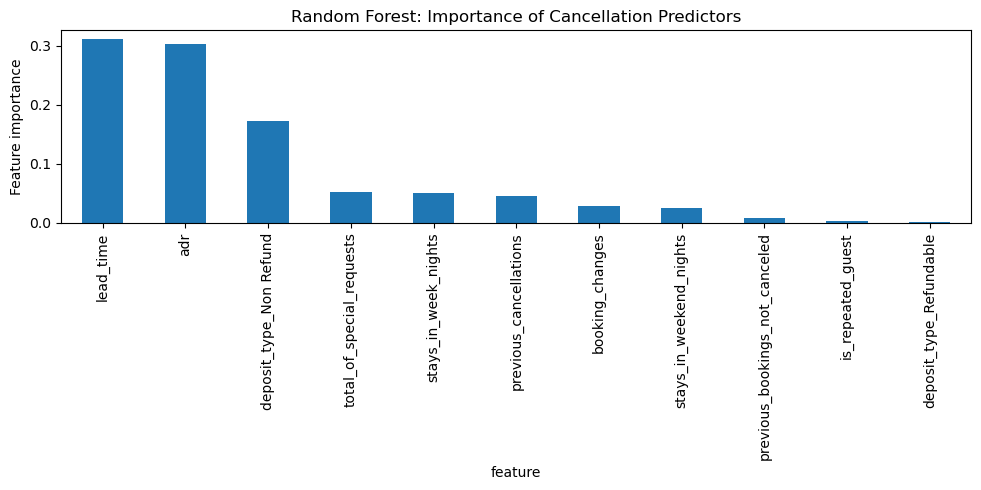

In [21]:
# Match each predictor with its impurity-based importance
importance_df = pd.DataFrame({
    "feature": X_train.columns,
    "importance": rf.feature_importances_
})

# Rank predictors from highest to lowest importance
importance_df = importance_df.sort_values(
    "importance",
    ascending=False
)

# Display the importance values
print(importance_df)

# Plot the ranked predictor importance
importance_df.plot(
    kind="bar",
    x="feature",
    y="importance",
    figsize=(10, 5),
    legend=False
)

# Add labels and adjust spacing
plt.ylabel("Feature importance")
plt.title("Random Forest: Importance of Cancellation Predictors")
plt.tight_layout()
plt.show()

# Importance describes split contributions, not direction or causation

In [22]:
# Evaluate the tree selected through cross-validation
print(
    "Tuned tree test accuracy:",
    round(accuracy_score(y_test, y_pred_best_tree), 3)
)

# Show correct and incorrect predictions for each class
print("Confusion matrix:")
print(confusion_matrix(y_test, y_pred_best_tree, labels=[0, 1]))

Tuned tree test accuracy: 0.799
Confusion matrix:
[[13615  1418]
 [ 3387  5458]]


In [23]:
# Compare the same model's performance across guest groups.
# This does not test whether predictor relationships differ between groups.

# Select first-time guests from the test data
X_first = X_test[X_test["is_repeated_guest"] == 0]

# Select the actual outcomes for those same bookings
y_first = y_test.loc[X_first.index]

# Select repeat guests and their actual outcomes
X_repeat = X_test[X_test["is_repeated_guest"] == 1]
y_repeat = y_test.loc[X_repeat.index]

# Use the trained random forest to predict each group's outcomes
pred_first = rf.predict(X_first)
pred_repeat = rf.predict(X_repeat)

# Find the most common outcome in each training group: 0 or 1
majority_first = y_train[X_train["is_repeated_guest"] == 0].mode().iloc[0]
majority_repeat = y_train[X_train["is_repeated_guest"] == 1].mode().iloc[0]

# Baseline accuracy: how often that majority prediction is correct on test data
print("First-time baseline accuracy:", (y_first == majority_first).mean())
print("Repeat baseline accuracy:", (y_repeat == majority_repeat).mean())

# Show the number of first-time bookings and actual cancellations
print("\nFIRST-TIME GUESTS")
print("Number of bookings:", len(y_first))
print("Actual cancellations:", y_first.sum())

# Accuracy: proportion of all predictions that are correct
print("Accuracy:", accuracy_score(y_first, pred_first))

# Precision: proportion of predicted cancellations that actually canceled
print("Precision:", precision_score(y_first, pred_first, zero_division=0))

# Recall: proportion of actual cancellations identified by the model
print("Recall:", recall_score(y_first, pred_first, zero_division=0))

# F1: combines precision and recall into one score
print("F1:", f1_score(y_first, pred_first, zero_division=0))

# Rows = actual outcomes; columns = predictions. Order: 0, 1
print("Confusion matrix:")
print(confusion_matrix(y_first, pred_first, labels=[0, 1]))

# Show the number of repeat bookings and actual cancellations
print("\nREPEAT GUESTS")
print("Number of bookings:", len(y_repeat))
print("Actual cancellations:", y_repeat.sum())

# Calculate the same performance metrics for repeat guests
# zero_division=0 returns 0 if a metric would involve division by zero
print("Accuracy:", accuracy_score(y_repeat, pred_repeat))
print("Precision:", precision_score(y_repeat, pred_repeat, zero_division=0))
print("Recall:", recall_score(y_repeat, pred_repeat, zero_division=0))
print("F1:", f1_score(y_repeat, pred_repeat, zero_division=0))

# Rows = actual outcomes; columns = predictions. Order: 0, 1
print("Confusion matrix:")
print(confusion_matrix(y_repeat, pred_repeat, labels=[0, 1]))

First-time baseline accuracy: 0.6220462217605817
Repeat baseline accuracy: 0.8549222797927462

FIRST-TIME GUESTS
Number of bookings: 23106
Actual cancellations: 8733
Accuracy: 0.8187050982428806
Precision: 0.7999735938737788
Recall: 0.6938051070651552
F1: 0.7431164530569694
Confusion matrix:
[[12858  1515]
 [ 2674  6059]]

REPEAT GUESTS
Number of bookings: 772
Actual cancellations: 112
Accuracy: 0.9546632124352331
Precision: 0.8969072164948454
Recall: 0.7767857142857143
F1: 0.8325358851674641
Confusion matrix:
[[650  10]
 [ 25  87]]
